Primeros registros:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst ar

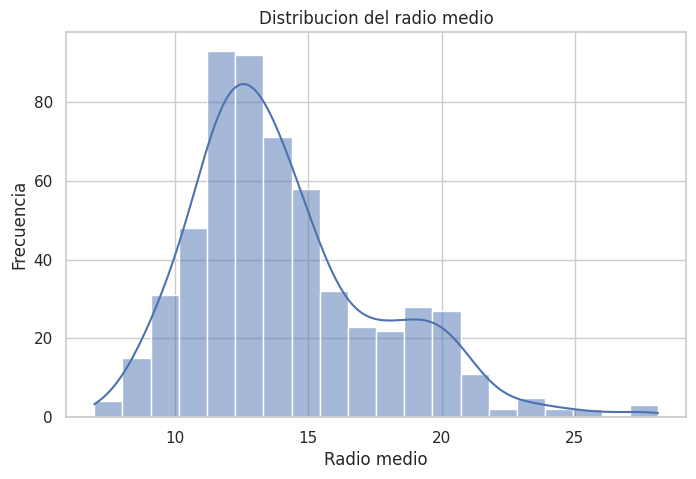

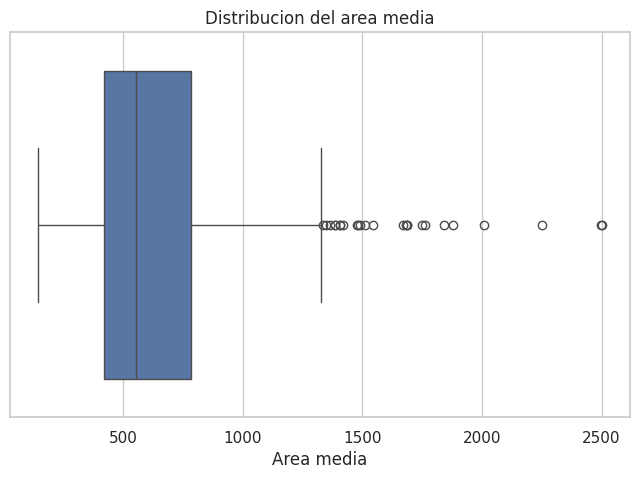

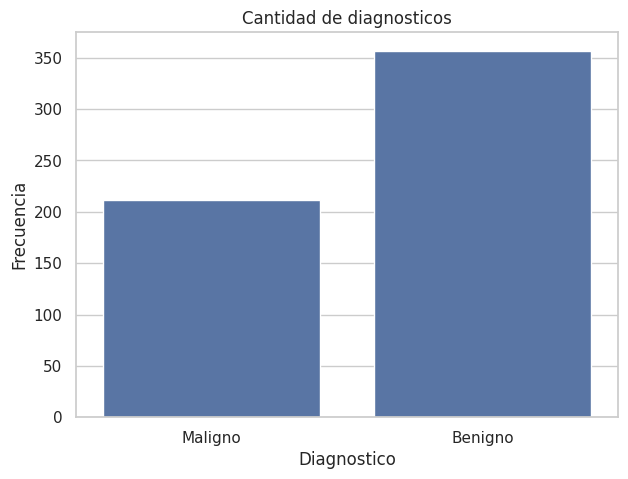

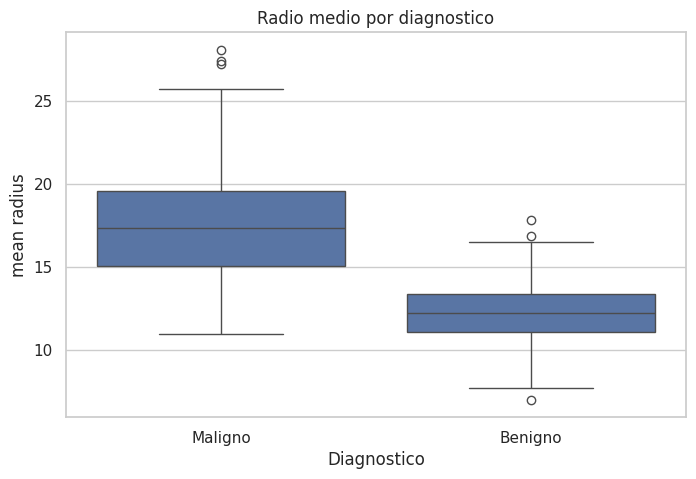

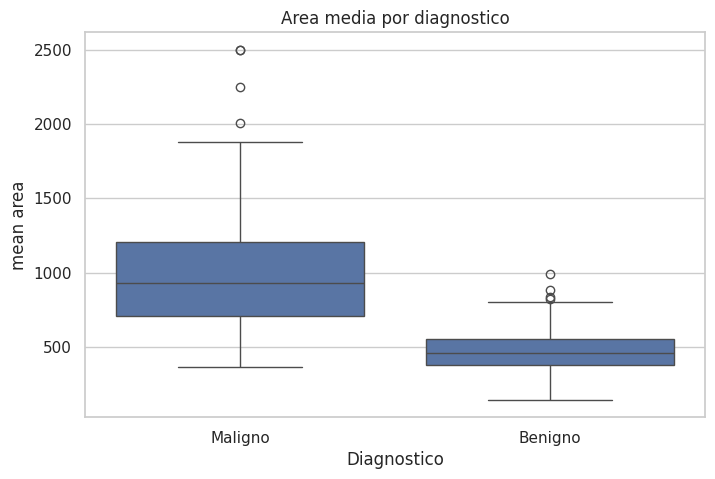

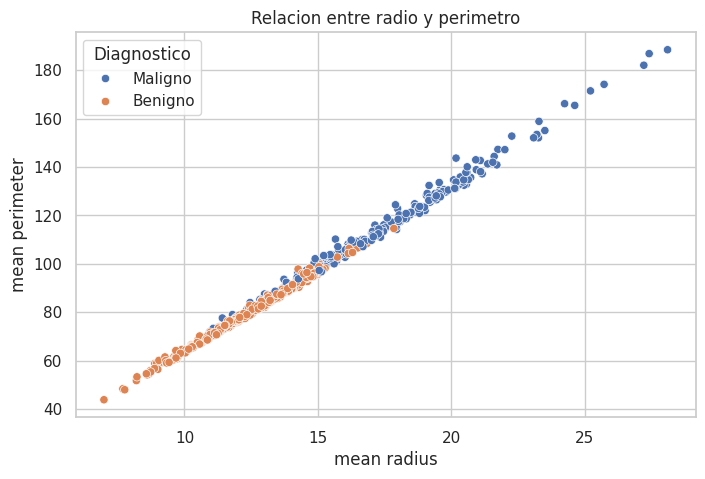

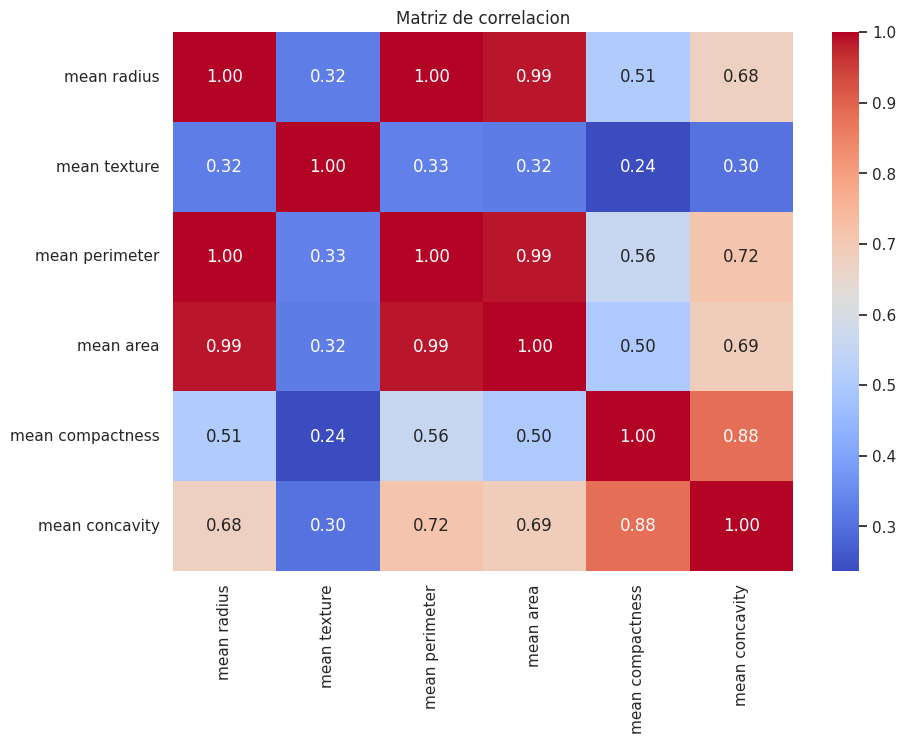

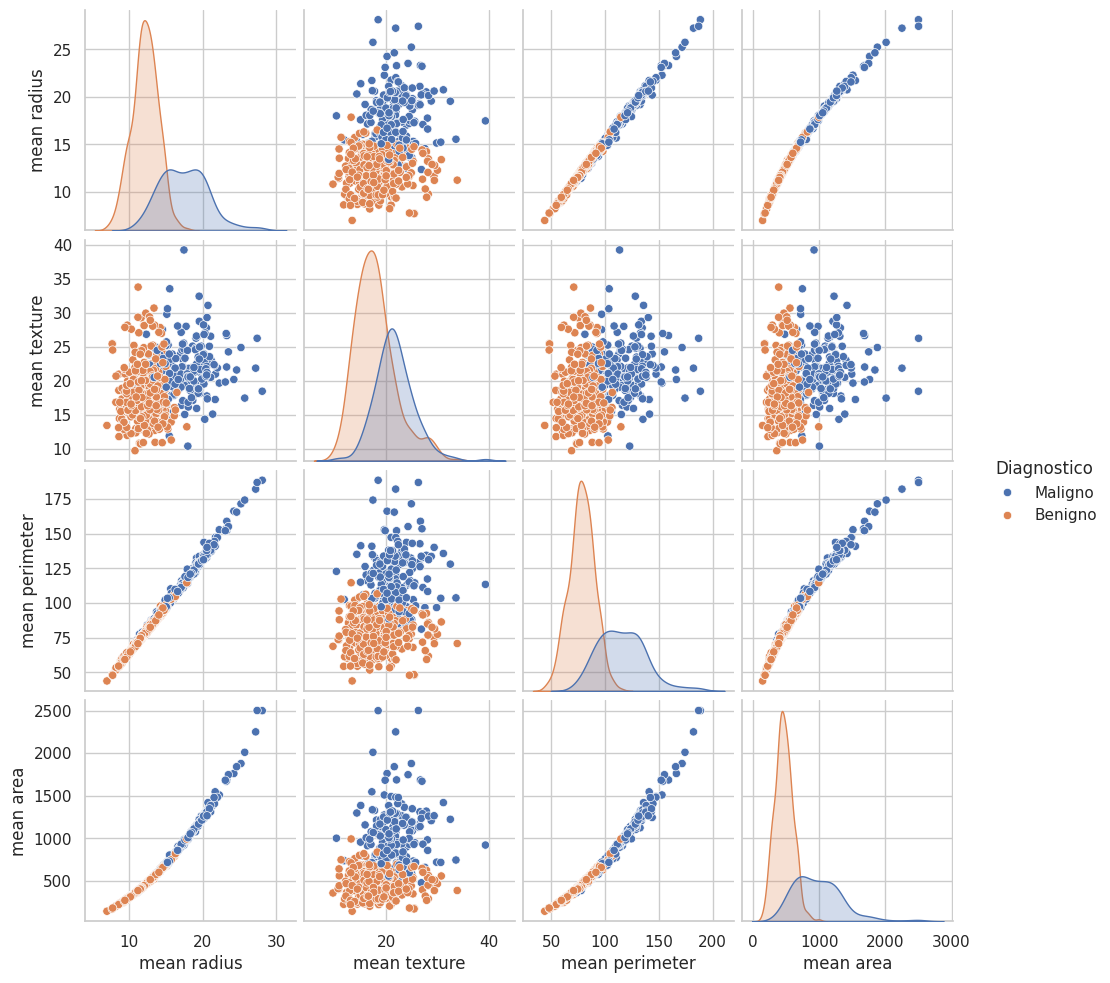


Analisis exploratorio terminado.


In [2]:

# Importar las librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

# Cargar el conjunto de datos
datos = load_breast_cancer(as_frame=True)

df = datos.frame.copy()

# Cambiar el nombre de la variable objetivo
df.rename(columns={"target": "Diagnostico"}, inplace=True)

# Convertir los valores de diagnostico
df["Diagnostico"] = df["Diagnostico"].map({
    0: "Maligno",
    1: "Benigno"
})

#  Conocer la estructura de los datos
print("Primeros registros:")
print(df.head())

print("\nDimensiones del conjunto de datos:")
print(df.shape)

print("\nInformacion general:")
print(df.info())

# 4. Estadisticas descriptivas
print("\nEstadisticas descriptivas:")
print(df.describe())

# 5. Revisar valores faltantes
print("\nValores faltantes:")
print(df.isnull().sum().sum())

# Revisar registros duplicados
print("\nRegistros duplicados:")
print(df.duplicated().sum())

# --------------------------------
# ANALISIS UNIVARIADO
# --------------------------------

# Histograma de la variable radius_mean
plt.figure(figsize=(8,5))
sns.histplot(df["mean radius"], bins=20, kde=True)
plt.title("Distribucion del radio medio")
plt.xlabel("Radio medio")
plt.ylabel("Frecuencia")
plt.show()

# Diagrama de caja
plt.figure(figsize=(8,5))
sns.boxplot(x=df["mean area"])
plt.title("Distribucion del area media")
plt.xlabel("Area media")
plt.show()

# Frecuencia de diagnosticos
plt.figure(figsize=(7,5))
sns.countplot(data=df, x="Diagnostico")
plt.title("Cantidad de diagnosticos")
plt.xlabel("Diagnostico")
plt.ylabel("Frecuencia")
plt.show()

# --------------------------------
# ANALISIS BIVARIADO
# --------------------------------

# Radio medio y diagnostico
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="Diagnostico", y="mean radius")
plt.title("Radio medio por diagnostico")
plt.show()

# Area media y diagnostico
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="Diagnostico", y="mean area")
plt.title("Area media por diagnostico")
plt.show()

# Radio medio y perimetro medio
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x="mean radius",
    y="mean perimeter",
    hue="Diagnostico"
)
plt.title("Relacion entre radio y perimetro")
plt.show()

# --------------------------------
# ANALISIS MULTIVARIADO
# --------------------------------

# Seleccionar variables numericas
variables = df[
    ["mean radius", "mean texture", "mean perimeter",
     "mean area", "mean compactness", "mean concavity"]
]

# Matriz de correlacion
correlacion = variables.corr()

plt.figure(figsize=(10,7))
sns.heatmap(
    correlacion,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Matriz de correlacion")
plt.show()

# Grafica de relaciones entre variables
sns.pairplot(
    df,
    vars=[
        "mean radius",
        "mean texture",
        "mean perimeter",
        "mean area"
    ],
    hue="Diagnostico"
)
plt.show()

print("\nAnalisis exploratorio terminado.")
